In [6]:
import numpy as np
from src.datasets import load_examples_mnist
from src.network import Network
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, LabelBinarizer
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
X, y = load_examples_mnist(n_samples=10000)
X_test, y_test = load_examples_mnist(n_samples=10000,
                                     images_path='data/mnist-handwritten-images/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte',
                                     labels_path='data/mnist-handwritten-images/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.9, random_state=1)

sizes = [X_train.shape[1], 30, 10]
activation_functions = ['sigmoid', 'sigmoid']
mini_batch_size = 10
max_epochs = 400

scaler = StandardScaler()
encoder = LabelBinarizer()

X_train_t = scaler.fit_transform(X_train).T
y_train_t = encoder.fit_transform(y_train).T
X_val_t = scaler.transform(X_val).T
y_val_t = encoder.transform(y_val).T

net = Network(sizes, activation_functions, mini_batch_size=mini_batch_size, cost="cross_entropy", init_method="naive",
              max_epochs=max_epochs, random_state=1, verbose=True, monitor_cost=True, monitor_accuracy=True, learning_rate=2.5)
net.fit(X_train_t, y_train_t, X_val_t, y_val_t)

epoch: 0, cost: 2.8870598237044565
epoch: 100, cost: 0.007972573273732663
epoch: 200, cost: 0.0033569126403364905
epoch: 300, cost: 0.0021253703527892975


,sizes,"[784, 30, ...]"
,activation_functions,"['sigmoid', 'sigmoid']"
,learning_rate,2.5
,cost,'cross_entropy'
,verbose,True
,random_state,1
,max_epochs,400
,monitor_cost,True
,monitor_accuracy,True
,mini_batch_size,10
,init_method,'naive'


In [8]:
def plot_train_test_accuracy(net: Network, ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()
    training_accuracy = np.array(net.training_accuracy)*100
    test_accuracy = np.array(net.val_accuracy)*100
    epochs = np.arange(len(training_accuracy))
    ax.plot(epochs,training_accuracy,c='blue',label='Training accuracy')
    ax.plot(epochs,test_accuracy,c='red',label='Test accuracy')
    ax.grid(visible=True, axis="both", which="major", linestyle="--", linewidth="0.5")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title("Validation Curve")

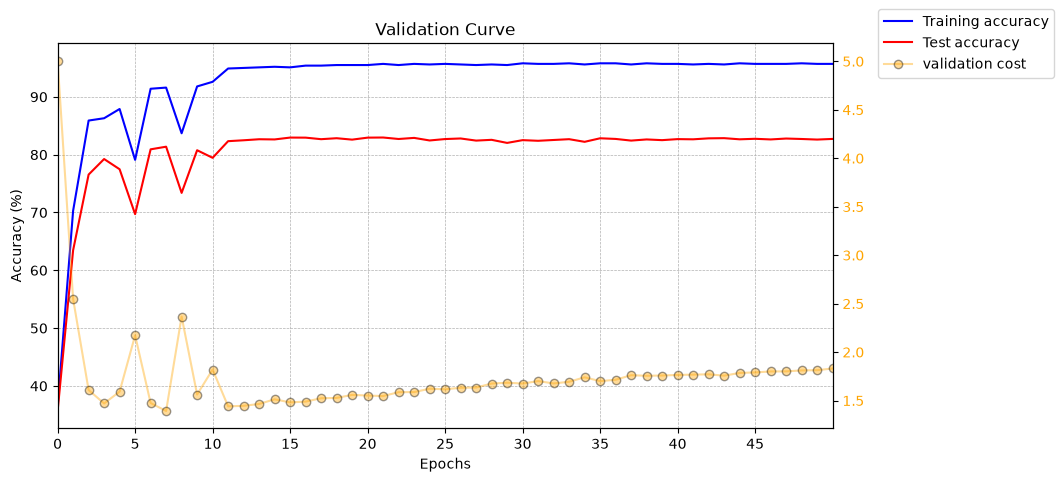

In [14]:
fig,ax = plt.subplots(figsize=(10,5))
plot_train_test_accuracy(net,ax=ax)
ax.set_xlim(0,50)
ax.set_xticks(range(0,50,5))
#ax.set_ylim(80,100+1)
ax_twin = ax.twinx()

costs = net.val_cost_cache
ax_twin.plot(range(len(costs)),costs, 'o-', label='validation cost', color='orange', mfc='orange', mec='k', alpha=0.4)
ax_twin.tick_params(axis='y', labelcolor='orange')
#ax_twin.set_ylim(0.2,1.0+0.01)

handle1, label1 = ax.get_legend_handles_labels()
handle2, label2 = ax_twin.get_legend_handles_labels()
ax_twin.legend(handle1+handle2, label1+label2, loc='center left', bbox_to_anchor=(1.05, 1.0),)
plt.show()